<a href="https://colab.research.google.com/github/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebooks/Week_06_QC_M34099_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Laboratory: Quantum Query Algorithms

[![View in GitHub](https://img.shields.io/badge/View%20in-GitHub-black?logo=github)](https://github.com/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebooks/Week_06_QC_M34099_Student.ipynb)

**M34099 Quantum Computing: Level 7 (2026/27)**

This laboratory contains three basic tasks:

1. calculate a mod-2 inner product;
2. use Deutsch-Jozsa to identify constant and balanced functions; and
3. use Bernstein-Vazirani to recover a hidden bit string.

> **Saving your work:** Select **File > Save a copy in Drive** before editing. Never place an API key or CRN in a visible notebook cell.

## Set up Google Colab

Run the installation cell once. If Colab requests a restart, select **Runtime > Restart session**, then continue from the imports cell.

In [1]:
# Install Qiskit, the Aer simulator, IBM Runtime, and drawing support.
%pip install -q "qiskit[visualization]" qiskit-aer qiskit-ibm-runtime pylatexenc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [2]:
# Import the Qiskit circuit and transpiler tools.
from qiskit import QuantumCircuit, transpile
# Import the local ideal simulator.
from qiskit_aer import AerSimulator
# Import the histogram plotting function.
from qiskit.visualization import plot_histogram

# Set the number of repeated measurements.
SHOTS = 1024
# Set a fixed seed for repeatable simulator results.
SEED = 34099
# Create the ideal simulator.
simulator = AerSimulator()
# Confirm that the setup is ready.
print("Setup complete.")

Setup complete.


## Task 1: Calculate a mod-2 inner product

For two bit strings, multiply matching bits and add the products using mod 2. In mod-2 addition, $1 + 1 = 0$.

The function below calculates $f_s(x)=s\cdot x\pmod 2$ for $s=1101$ and $x=1011$.

In [3]:
# Store the hidden bit string.
secret = "1101"
# Store the input bit string.
input_bits = "1011"
# Multiply each pair of matching bits.
products = [int(s) * int(x) for s, x in zip(secret, input_bits)]
# Add the products and keep only the remainder after division by two.
answer = sum(products) % 2
# Display the four pairwise products.
print("Pairwise products:", products)
# Display the mod-2 result.
print("Mod-2 inner product:", answer)

Pairwise products: [1, 0, 0, 1]
Mod-2 inner product: 0


### Result

The products are `1, 0, 0, 1`. Their ordinary sum is 2, and $2\pmod 2=0$. Therefore, $f_s(x)=0$.

## Task 2: Deutsch-Jozsa with one input qubit

Deutsch-Jozsa decides whether a promised function is constant or balanced. A final result of `0` means constant. A final result of `1` means balanced.

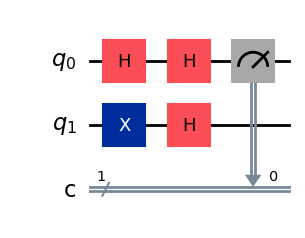

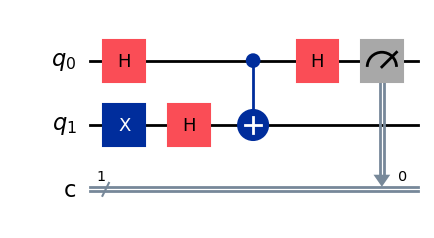

Deutsch-Jozsa results: {'Constant': {'0': 1024}, 'Balanced': {'1': 1024}}


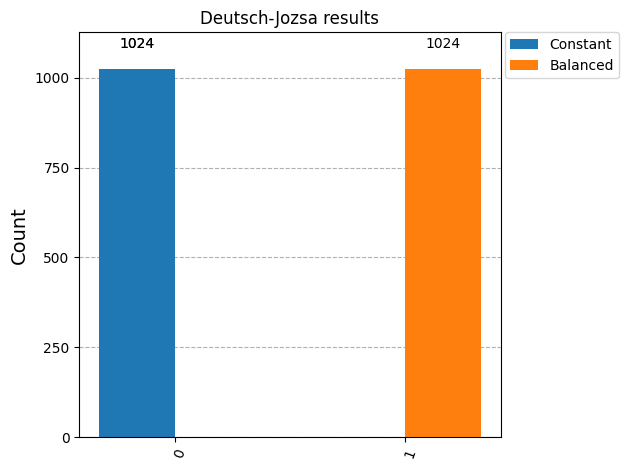

In [4]:
# Create a function that builds a small Deutsch-Jozsa circuit.
def make_dj_circuit(function_type):
    # Create one input qubit, one ancilla qubit, and one classical bit.
    circuit = QuantumCircuit(2, 1)
    # Prepare the ancilla qubit in state one.
    circuit.x(1)
    # Apply H to both qubits to create superposition.
    circuit.h([0, 1])
    # Use a CNOT as the balanced oracle.
    if function_type == "balanced":
        # Make the function output depend on the input.
        circuit.cx(0, 1)
    # Apply H to the input qubit to create interference.
    circuit.h(0)
    # Measure only the input qubit.
    circuit.measure(0, 0)
    # Return the completed circuit.
    return circuit

# Build a circuit with a constant oracle.
dj_constant = make_dj_circuit("constant")
# Build a circuit with a balanced oracle.
dj_balanced = make_dj_circuit("balanced")
# Store both circuits and their labels.
dj_circuits = {"Constant": dj_constant, "Balanced": dj_balanced}
# Create an empty dictionary for the results.
dj_counts = {}

# Run each circuit on the ideal simulator.
for label, circuit in dj_circuits.items():
    # Convert the circuit for the simulator.
    compiled = transpile(circuit, simulator)
    # Run the circuit many times.
    result = simulator.run(compiled, shots=SHOTS, seed_simulator=SEED).result()
    # Store the measurement counts.
    dj_counts[label] = result.get_counts()

# Display the constant circuit.
display(dj_constant.draw("mpl"))
# Display the balanced circuit.
display(dj_balanced.draw("mpl"))
# Display the counts.
print("Deutsch-Jozsa results:", dj_counts)
# Display the results as a histogram.
display(plot_histogram(list(dj_counts.values()), legend=list(dj_counts.keys()), title="Deutsch-Jozsa results"))

### Result

The constant circuit returns `0`, while the balanced circuit returns `1`. Deutsch-Jozsa identifies the function type with one oracle query.

## Task 3: Recover a hidden string with Bernstein-Vazirani

The secret is `110`. The oracle adds a CNOT for each secret bit equal to 1. The algorithm should recover the complete secret with one oracle query.

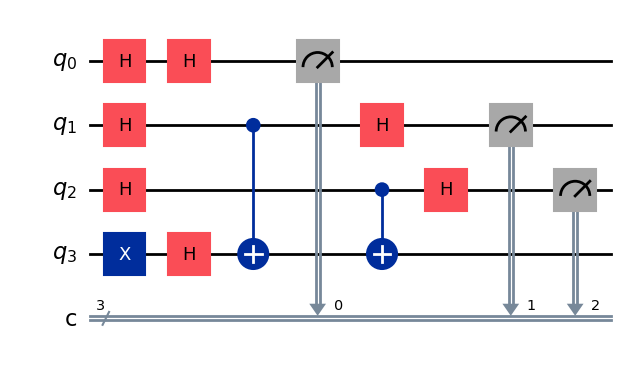

Expected secret: 110
Recovered secret: 110


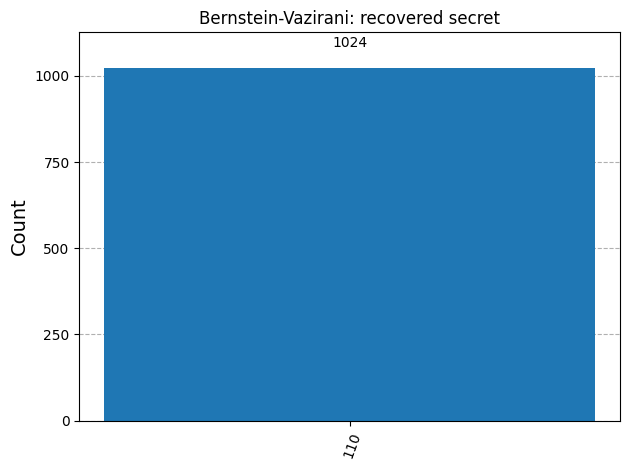

In [5]:
# Create a function that builds a Bernstein-Vazirani circuit.
def make_bv_circuit(secret):
    # Count the number of bits in the secret.
    number_of_bits = len(secret)
    # Create input qubits, one ancilla qubit, and classical bits.
    circuit = QuantumCircuit(number_of_bits + 1, number_of_bits)
    # Store the position of the ancilla qubit.
    ancilla = number_of_bits
    # Prepare the ancilla qubit in state one.
    circuit.x(ancilla)
    # Apply H to every qubit to create superposition.
    circuit.h(range(number_of_bits + 1))
    # Read the secret from right to left to match Qiskit's bit order.
    for qubit, bit in enumerate(reversed(secret)):
        # Add a CNOT only when the secret bit is one.
        if bit == "1":
            # Connect the selected input qubit to the ancilla.
            circuit.cx(qubit, ancilla)
    # Apply H to all input qubits to create interference.
    circuit.h(range(number_of_bits))
    # Measure the input qubits.
    circuit.measure(range(number_of_bits), range(number_of_bits))
    # Return the completed circuit.
    return circuit

# Choose a three-bit hidden string.
BV_SECRET = "110"
# Build the Bernstein-Vazirani circuit.
bv_circuit = make_bv_circuit(BV_SECRET)
# Display the circuit.
display(bv_circuit.draw("mpl"))
# Convert the circuit for the simulator.
compiled_bv = transpile(bv_circuit, simulator)
# Run the circuit many times.
bv_result = simulator.run(compiled_bv, shots=SHOTS, seed_simulator=SEED).result()
# Extract the measurement counts.
simulator_bv_counts = bv_result.get_counts()
# Read the most frequent result.
recovered_secret = max(simulator_bv_counts, key=simulator_bv_counts.get)
# Display the expected secret.
print("Expected secret:", BV_SECRET)
# Display the recovered secret.
print("Recovered secret:", recovered_secret)
# Display the histogram.
display(plot_histogram(simulator_bv_counts, title="Bernstein-Vazirani: recovered secret"))

### Simulator result

The simulator returns `110`, so the hidden string is recovered correctly. Bernstein-Vazirani uses one quantum oracle query. A deterministic classical method may need three queries for a three-bit secret.

## Optional: Run Task 3 on IBM quantum hardware

Run this section only after your tutor confirms that IBM Quantum Classroom access is ready. The same Bernstein-Vazirani circuit is used so the simulator and hardware results can be compared directly.

- Keep `RUN_ON_REAL_HARDWARE = False` until access is ready.
- Enter your API key and classroom CRN only through the hidden prompts.
- Never save credentials in the notebook, Google Drive, Moodle or GitHub.

In [6]:
# Keep real-hardware execution disabled until access is ready.
RUN_ON_REAL_HARDWARE = False
# Display the current hardware setting.
print("Real-hardware execution enabled:", RUN_ON_REAL_HARDWARE)

Real-hardware execution enabled: False


In [7]:
# Continue only when real-hardware execution is enabled.
if RUN_ON_REAL_HARDWARE:
    # Import secure hidden-input support.
    from getpass import getpass
    # Import the IBM Quantum Runtime connection.
    from qiskit_ibm_runtime import QiskitRuntimeService
    # Import the device-aware circuit pass manager.
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    # Import the IBM Runtime Sampler interface.
    from qiskit_ibm_runtime import SamplerV2

    # Connect only once during the current Colab session.
    if "ibm_service" not in globals():
        # Request the API key without displaying it.
        ibm_api_key = getpass("Enter your personal IBM Cloud API key: ")
        # Request the classroom CRN without displaying it.
        classroom_crn = getpass("Enter the classroom instance CRN: ")
        # Connect to the classroom instance.
        ibm_service = QiskitRuntimeService(channel="ibm_quantum_platform", token=ibm_api_key, instance=classroom_crn)
        # Remove the plaintext credential variables.
        del ibm_api_key, classroom_crn

    # Select an operational quantum computer with a short queue.
    backend = ibm_service.least_busy(operational=True, simulator=False)
    # Display the selected device.
    print("Selected backend:", backend.name)
    # Create a pass manager for the selected device.
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    # Convert the Bernstein-Vazirani circuit for the real device.
    hardware_circuit = pass_manager.run(bv_circuit)
    # Create the Runtime Sampler.
    sampler = SamplerV2(mode=backend)
    # Submit the circuit in one job.
    hardware_job = sampler.run([hardware_circuit], shots=SHOTS)
    # Display the job identifier.
    print("Job ID:", hardware_job.job_id())
    # Wait for the job and collect the result.
    hardware_result = hardware_job.result()
    # Extract the counts from the classical register.
    hardware_bv_counts = dict(hardware_result[0].data.c.get_counts())
    # Display the hardware counts.
    print("Hardware results:", hardware_bv_counts)
    # Compare simulator and hardware results.
    display(plot_histogram([dict(simulator_bv_counts), hardware_bv_counts], legend=["Ideal simulator", f"IBM {backend.name}"], title="Bernstein-Vazirani comparison"))
# Skip the hardware job when the safety switch is off.
else:
    # Confirm that no hardware job was submitted.
    print("No hardware job submitted.")

No hardware job submitted.


### Hardware result

The ideal simulator should return only `110`. Real hardware may also produce a small number of other strings because physical qubits and gates are noisy. The most frequent hardware result should normally remain `110`.

## References

- IBM Quantum Learning, *Quantum query algorithms*: https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms
- IBM Quantum Documentation, *Run jobs with Qiskit Runtime*: https://quantum.cloud.ibm.com/docs/guides/run-jobs
- Qiskit Aer documentation: https://qiskit.github.io/qiskit-aer/

Accessed 2 November 2026.